# Module Assignment — Exploratory Data Analysis on Hotel Bookings

## Case Study: Hotel Bookings

In this assignment you'll apply everything from this module to a **large, genuinely messy** real-world dataset: **119,390 hotel bookings with 32 columns**.

You will practise the full EDA workflow:

1. **Exploring / diagnosing** the data
2. **Cleaning** — missing values, duplicates, wrong data types, invalid values
3. **Visualizing** with matplotlib
4. **Manipulating** — sorting, filtering, new columns, `groupby`, `pivot_table`, `crosstab`
5. **Drawing conclusions**

**This dataset is deliberately challenging** — it has 4 columns with missing data (one is ~94% empty!), ~32,000 duplicate rows, dates stored as text, and some physically impossible values. Read each prompt carefully and think about *why* a step is needed, not just *how*.

### Instructions

- Write your **full code** in the empty cell below each exercise
- Some exercises ask a question in **markdown** — answer it in a comment or a short written note.
- Work through the notebook **in order**: later sections rely on the cleaned DataFrame from earlier ones.
- Worked answers are in **`Module_Assignment_Hotel_Bookings_Solutions.ipynb`** — try hard before peeking.

### Key columns

| Column | Meaning |
|---|---|
| `hotel` | Resort Hotel or City Hotel |
| `is_canceled` | 1 = booking was cancelled, 0 = not |
| `lead_time` | Days between booking and arrival |
| `arrival_date_month` | Month of arrival (text, e.g. "July") |
| `adults` / `children` / `babies` | Number of guests of each type |
| `meal`, `country`, `market_segment`, `customer_type` | Categorical descriptors |
| `adr` | Average Daily Rate (price per night) |
| `agent` / `company` | IDs of the booking agent / company (lots of missing) |
| `reservation_status_date` | Date of the last status change (text) |

## Import Libraries

**Exercise 0.** Import the required libraries.

In [6]:
# Your code here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

## Load Dataset

**Exercise 1.** Read `hotel_bookings.csv` into a DataFrame called `df` and display the first 5 rows.

In [4]:
# Your code here
df = pd.read_csv('../data/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


# 1. Exploring / Diagnosing the Data

**Exercise 2.** Report the dataset's **shape** (rows, columns). Then  inspect column names, non-null counts, and dtypes.

In [8]:
# Your code here
df.shape, df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

((119390, 32), None)

**Exercise 3.** Show the summary statistics for the **numeric** columns `. Look at the `adr` column — what is suspicious about its **minimum** value?

In [ ]:
# Your code here
df.describe()
# There is a negative value!

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


**Exercise 4.** Build a table showing, **for every column**, the number of missing values **and** the percentage missing — sorted from most to least missing. Which columns are the worst?

In [ ]:
# Your code here
table = pd.DataFrame()
table['number of missing values'] = df.isnull().sum()
table['percentage'] = table['number of missing values']/len(df)
table
# Comapny column has a large missing values, it's about 95%

,number of missing values,percentage
hotel,0,0.000000
is_canceled,0,0.000000
lead_time,0,0.000000
arrival_date_year,0,0.000000
arrival_date_month,0,0.000000
arrival_date_week_number,0,0.000000
arrival_date_day_of_month,0,0.000000
stays_in_weekend_nights,0,0.000000
stays_in_week_nights,0,0.000000
adults,0,0.000000


**Exercise 5.** For the categorical columns `hotel`, `meal`, `customer_type` and `market_segment`, print the **count of each unique value**.

In [19]:
cols = ['hotel', 'meal', 'customer_type', 'market_segment']

for col in cols:
    print(col,": ", df[col].value_counts().unique())

hotel :  [79330 40060]
meal :  [92310 14463 10650  1169   798]
customer_type :  [89613 25124  4076   577]
market_segment :  [56477 24219 19811 12606  5295   743   237     2]


# 2. Cleaning the Data

Work on a copy so the raw data stays intact: start this section with `df_clean = df.copy()`.

**Exercise 6.** Make a copy called `df_clean`. Then handle the missing values:

- `children` → fill missing with `0`
- `country` → fill missing with `"Unknown"`
- `company` and `agent` are mostly empty → **drop both columns**

Confirm there are no missing values left.

In [35]:
# Your code here
df_clean = df.copy()
df_clean['children'] = df_clean['children'].fillna(0)
df_clean['country'] = df_clean['country'].fillna("Unknown")
df_clean.drop(['company','agent'], axis=1, inplace=True)
df_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 30 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119390 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

**Exercise 7.** How many **fully duplicated rows** does `df_clean` contain? Remove them, then confirm the count is now 0 and report the new shape.

In [36]:
# Your code here
df_clean.duplicated().sum() # 32020 rows duplicated
df_clean = df_clean.drop_duplicates()
df_clean.duplicated().sum(), df_clean.shape

(np.int64(0), (87370, 30))

**Exercise 8.** Fix the data types:

- Convert `reservation_status_date` from text to a real **datetime**.
- `children` was a float because of the missing values — now convert it to **int**.

Verify with `.dtypes`.

In [41]:
# Your code here
df_clean['reservation_status_date'] = df_clean['reservation_status_date'].astype('datetime64[s]')
df_clean['children'] = df_clean['children'].astype(int)
df_clean['reservation_status_date'].dtype, df_clean['children'].dtype

(dtype('<M8[s]'), dtype('int64'))

**Exercise 9.** Remove **invalid values**:

- The `adr` (price) cannot be negative — keep only rows where `adr >= 0`.
- A booking with **zero guests** makes no sense. Create a `total_guests = adults + children + babies` column, then drop rows where `total_guests == 0`.

Report how many rows remain.

In [46]:
# Your code here
df_clean = df_clean[df_clean['adr'] >=0]
df_clean['total_guests'] = df_clean['adults'] + df_clean['children'] + df_clean['babies']
df_clean = df_clean[df_clean['total_guests'] !=0]
df_clean.shape

(87203, 31)

# 3. Visualizing the Data 

**Exercise 10.** Plot a **histogram** of `lead_time` (use `bins=50`). Add a title and axis labels. What does the shape tell you about how far in advance people book?

Text(0, 0.5, 'Frequency')

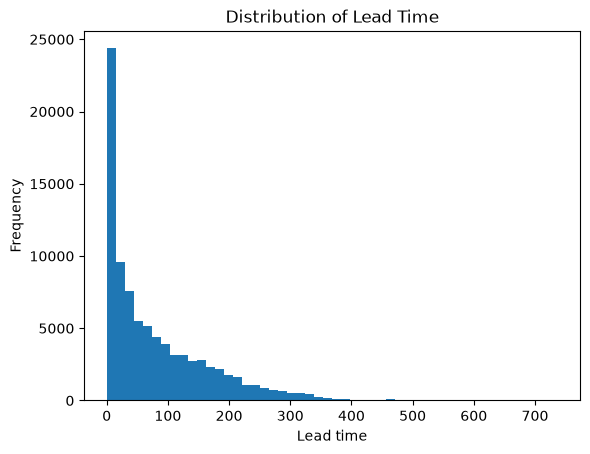

In [54]:
# Your code here
fig, ax = plt.subplots()
histogram = ax.hist(df_clean['lead_time'], bins=50)
ax.set_title('Distribution of Lead Time')
ax.set_xlabel('Lead time')
ax.set_ylabel('Frequency')

# most people book a hotel a few days before they arrival

**Exercise 11.** Make a **bar chart** of the number of bookings per `hotel` (Resort vs City). Use `value_counts()` and label the chart.

<BarContainer object of 2 artists>

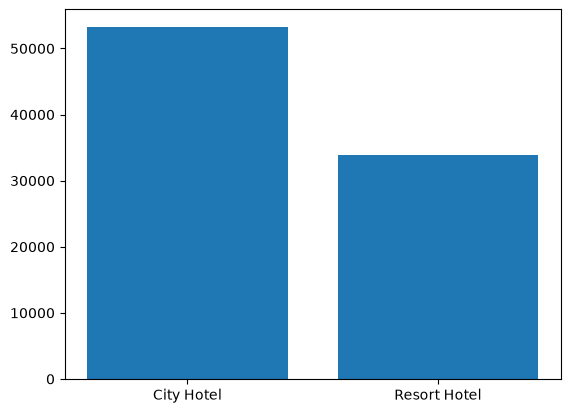

In [ ]:
# Your code here
plt.bar(df_clean['hotel'].value_counts().index, df_clean['hotel'].value_counts().values);

**Exercise 12.** Draw a **scatter plot** of `lead_time` (x) vs `adr` (y). Use `alpha` and a small marker size `s` so the dense cloud is readable.

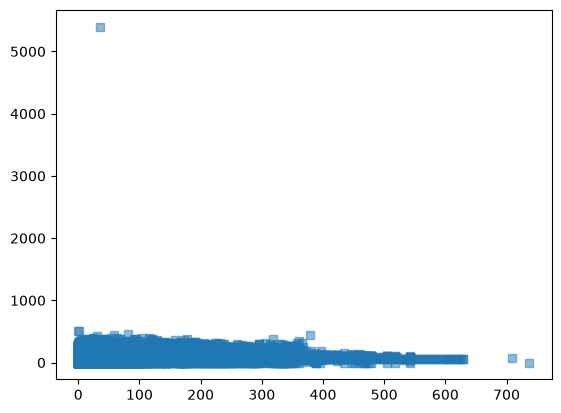

In [62]:
# Your code here
plt.scatter(df_clean['lead_time'], df_clean['adr'], alpha=0.5, marker='s')

**Exercise 13.** Build a **2×2 grid of subplots** (`figsize=(12, 9)`):

- histogram of `adr`
- histogram of `total_guests`
- bar chart of `customer_type` counts
- bar chart of `is_canceled` counts (0 vs 1)

Give each subplot a title and call `fig.tight_layout()`.

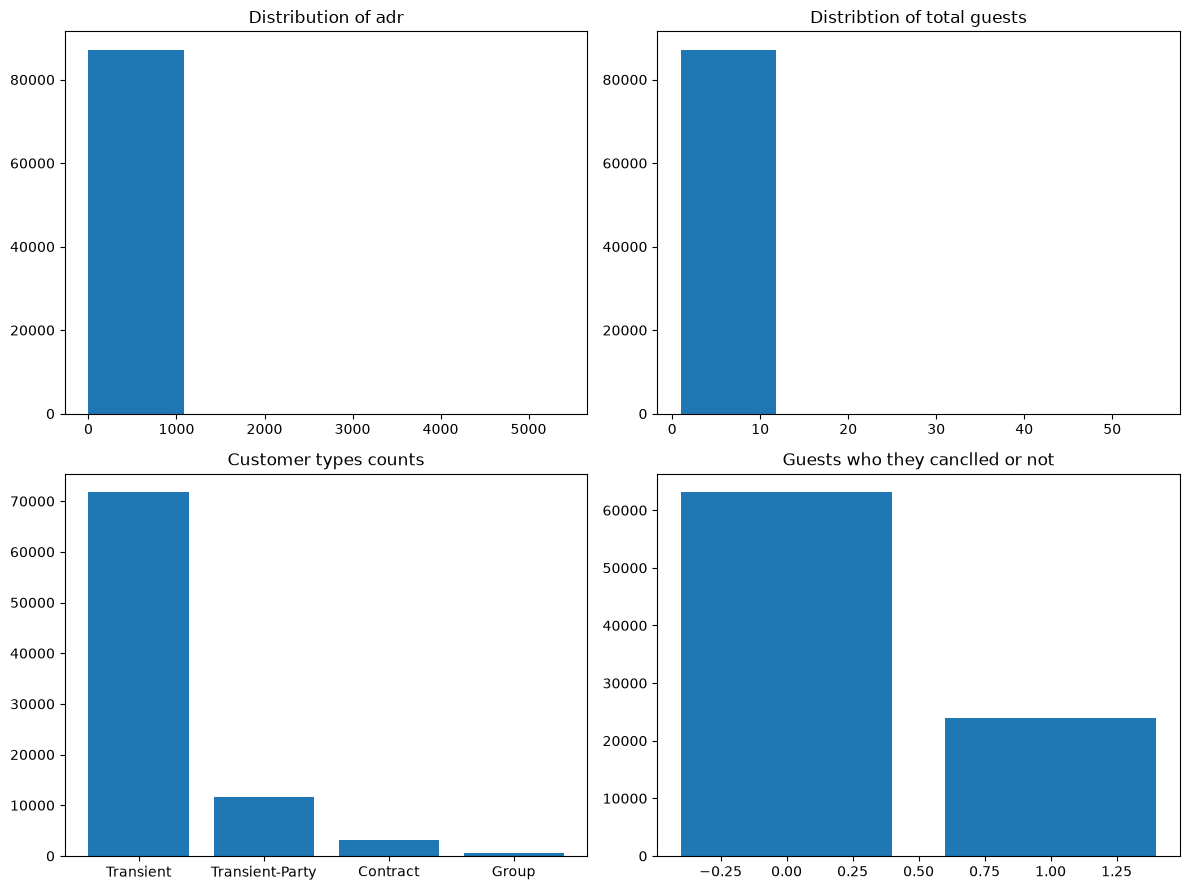

In [77]:
# Your code here
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2,2, figsize=(12,9))
ax1.hist(df_clean['adr'], bins=5)
ax1.set_title('Distribution of adr')
fig.tight_layout()

ax2.hist(df_clean['total_guests'], bins=5)
ax2.set_title('Distribtion of total guests')
fig.tight_layout()

ax3.bar(df_clean['customer_type'].value_counts().index, df_clean['customer_type'].value_counts().values)
ax3.set_title('Customer types counts')
fig.tight_layout()

ax4.bar(df_clean['is_canceled'].value_counts().index, df_clean['is_canceled'].value_counts().values)
ax4.set_title('Guests who they canclled or not')
fig.tight_layout()

**Exercise 14.** Compute the **correlation matrix** of the numeric columns and display it as a **heatmap** using `ax.imshow(..., cmap="coolwarm")`. Add a colorbar and tick labels with the column names.

*Tip: `df_clean.select_dtypes('number').corr()` gives the matrix; use `ax.set_xticks`/`set_yticks` + `set_xticklabels`/`set_yticklabels` for the labels.*

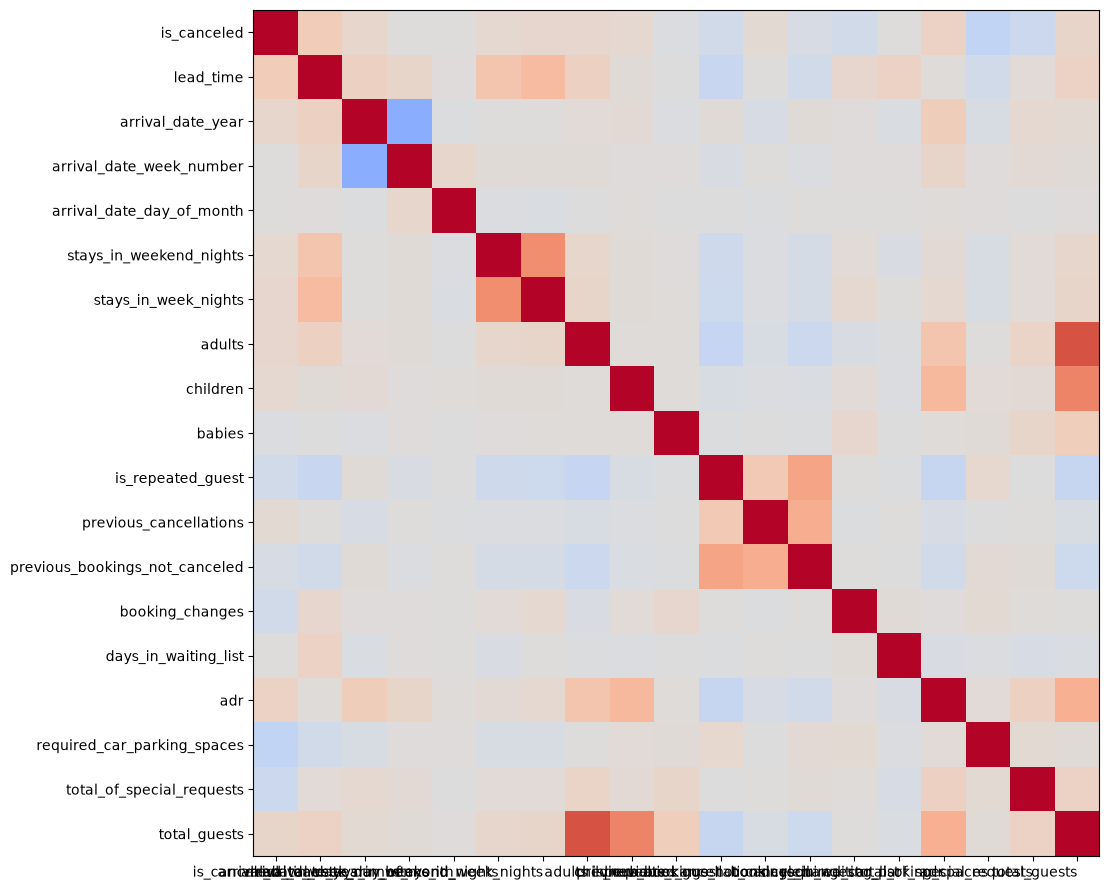

In [ ]:
# Your code here
corr = df_clean.select_dtypes('number').corr()
cols = corr.columns

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, ha="right")
ax.set_yticklabels(cols)
fig.tight_layout()
plt.show()

# 4. Manipulating the Data

**Exercise 15.** **Sort** `df_clean` by `adr` in descending order and show the **top 10** most expensive bookings (columns `hotel`, `arrival_date_month`, `adr`).

In [89]:
# Your code here
df_clean.sort_values(['adr','hotel','arrival_date_month'], ascending=False).head(10)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests
48515,City Hotel,1,35,2016,March,13,25,0,1,2,...,1,Non Refund,0,Transient,5400.00,0,0,Canceled,2016-02-19,2
111403,City Hotel,0,0,2017,May,19,9,0,1,1,...,0,No Deposit,0,Transient,510.00,0,0,Check-Out,2017-05-10,1
15083,Resort Hotel,0,1,2015,July,29,15,0,1,2,...,0,No Deposit,0,Transient,508.00,1,0,Check-Out,2015-07-16,2
103912,City Hotel,0,81,2016,December,53,31,1,1,2,...,1,No Deposit,0,Transient-Party,451.50,0,4,Check-Out,2017-01-02,4
13142,Resort Hotel,1,378,2017,August,31,1,4,10,2,...,0,No Deposit,0,Transient,450.00,0,0,Canceled,2016-07-22,2
13391,Resort Hotel,1,59,2017,August,33,13,2,4,2,...,1,No Deposit,0,Transient,437.00,0,0,Canceled,2017-08-03,4
39155,Resort Hotel,0,31,2017,August,31,1,2,6,2,...,0,No Deposit,0,Transient,426.25,0,2,Check-Out,2017-08-09,4
39568,Resort Hotel,0,104,2017,August,33,17,2,3,3,...,2,No Deposit,0,Transient,402.00,0,1,Check-Out,2017-08-22,4
39118,Resort Hotel,0,26,2017,July,31,31,3,5,3,...,1,No Deposit,0,Transient,397.38,0,1,Check-Out,2017-08-08,5
13323,Resort Hotel,1,116,2017,August,32,9,2,8,2,...,3,No Deposit,0,Transient,392.00,0,0,Canceled,2017-04-17,3


**Exercise 16.** Use boolean filtering to select **City Hotel bookings that were cancelled** (`hotel == "City Hotel"` **and** `is_canceled == 1`). How many are there?

In [ ]:
# Your code here
df_clean[(df_clean['hotel']=='City Hotel') & (df_clean['is_canceled']==1)]
# There are 16033 rows

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,total_guests
40061,City Hotel,1,88,2015,July,27,1,0,4,2,...,0,No Deposit,0,Transient,76.5,0,1,Canceled,2015-07-01,2
40062,City Hotel,1,65,2015,July,27,1,0,4,1,...,0,No Deposit,0,Transient,68.0,0,1,Canceled,2015-04-30,1
40063,City Hotel,1,92,2015,July,27,1,2,4,2,...,0,No Deposit,0,Transient,76.5,0,2,Canceled,2015-06-23,2
40064,City Hotel,1,100,2015,July,27,2,0,2,2,...,0,No Deposit,0,Transient,76.5,0,1,Canceled,2015-04-02,2
40065,City Hotel,1,79,2015,July,27,2,0,3,2,...,0,No Deposit,0,Transient,76.5,0,1,Canceled,2015-06-25,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108829,City Hotel,1,25,2017,May,18,6,2,1,1,...,0,No Deposit,0,Transient,125.0,0,0,No-Show,2017-05-06,1
111355,City Hotel,1,4,2017,June,23,5,1,0,1,...,0,No Deposit,0,Transient,65.0,0,0,Canceled,2017-06-05,1
111924,City Hotel,1,7,2017,May,22,31,0,1,1,...,0,No Deposit,0,Transient,65.0,0,0,Canceled,2017-05-31,1
111925,City Hotel,1,6,2017,July,29,17,1,0,1,...,0,No Deposit,0,Transient,65.0,0,0,No-Show,2017-07-17,1


**Exercise 17.** Group by `hotel` and compute the **mean `adr`** and the **cancellation rate** (mean of `is_canceled`) for each hotel. Which hotel cancels more?

In [101]:
# Your code here
df_clean.groupby(['hotel'])[['adr','is_canceled']].mean()
# City Hotel is more canceled than Resort Hotel

,adr,is_canceled
hotel,,
City Hotel,111.274295,0.301033
Resort Hotel,99.073648,0.234864


**Exercise 18.** Produce a **grouped summary**: group by **both** `hotel` and `customer_type`, and aggregate `adr` with **mean, median and count** in one call.

In [103]:
# Your code here
df_clean.groupby(['hotel','customer_type'])['adr'].agg(mean='mean', median='median', count='count')

mean   median  count
hotel        customer_type                              
City Hotel   Contract         107.854431  103.840   1467
             Group             93.995874   85.000    269
             Transient        114.296209  108.000  44513
             Transient-Party   93.466617   90.000   7011
Resort Hotel Contract          79.693843   72.950   1668
             Group             75.741213   61.600    272
             Transient        103.824229   84.135  27330
             Transient-Party   79.565530   66.000   4673

**Exercise 19.** Build a **`crosstab`** of `hotel` (rows) vs `is_canceled` (columns) to count bookings in each combination.

In [104]:
# Your code here
pd.crosstab(df_clean['hotel'], df_clean['is_canceled'])

is_canceled,0,1
hotel,,
City Hotel,37227,16033
Resort Hotel,25971,7972


**Exercise 20.** Build a **`pivot_table`** with `hotel` as the index, `is_canceled` as the columns, and the **mean `adr`** as the values. Do cancelled bookings have a different average price?

In [110]:
# Your code here
pd.pivot_table(df_clean, index='hotel', columns='is_canceled', values=['adr'], aggfunc='mean')


adr            
is_canceled            0           1
hotel                               
City Hotel    108.643530  117.382665
Resort Hotel   93.016028  118.808024

# 5. Putting It Together

**Exercise 21.** Compute the **cancellation rate per arrival month** and plot it as a bar chart, with the months in **calendar order** (January → December), not alphabetical.

*Tip: group by `arrival_date_month`, take the mean of `is_canceled`, then `.reindex(...)` with a list of month names in order.*

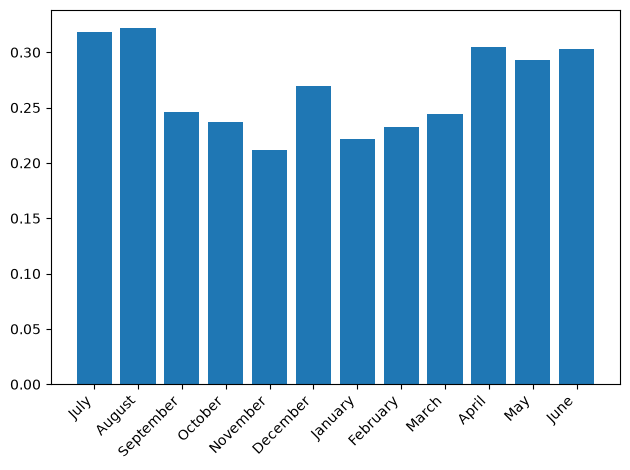

In [131]:
# Your code here
list_of_month = df_clean['arrival_date_month'].unique()
values = df_clean.groupby('arrival_date_month')['is_canceled'].mean().reindex(list_of_month)


plt.bar(list_of_month, values);
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## 🏆 Challenge Exercises

These are open-ended — combine the skills above and explain what you find in a short comment.

1. **Total nights & revenue:** create `total_nights = stays_in_weekend_nights + stays_in_week_nights`, then estimate revenue as `adr * total_nights`. Which `market_segment` brings the most total estimated revenue? (Remember: cancelled bookings earn nothing — decide how to handle them and justify it.)
2. **Lead time vs cancellation:** bin `lead_time` into buckets (e.g. `pd.cut` at 0, 30, 90, 180, 365, ∞) and show the cancellation rate per bucket. Do bookings made far in advance get cancelled more?
3. **Repeat guests:** compare the cancellation rate of repeated guests (`is_repeated_guest == 1`) vs new guests. Visualize the difference.
4. **Your own question:** pose one question about the data, answer it with code + a plot, and write a one-line conclusion.

In [189]:
# Your challenge code here
# 1
df_clean['total_nights'] = df_clean['stays_in_weekend_nights'] + df_clean['stays_in_week_nights']
df_clean['revenue'] = df_clean['adr'] * df_clean['total_nights']
[df_clean[df_clean['is_canceled']==0].groupby('market_segment')['revenue'].max()]

[market_segment
 Aviation         1650.00
 Complementary     767.55
 Corporate        3910.00
 Direct           7590.00
 Groups           1680.00
 Offline TA/TO    3477.60
 Online TA        3791.00
 Name: revenue, dtype: float64]

In [190]:
# 2
df_clean.groupby(pd.cut(df_clean['lead_time'], bins=[0, 30, 90, 180, 365, np.inf]))['is_canceled'].agg(mean='mean', count= 'count')
# The results show that the longer the booking period, the higher the cancellation rate


,mean,count
lead_time,,
"(0.0, 30.0]",0.186279,28613
"(30.0, 90.0]",0.320477,22713
"(90.0, 180.0]",0.350036,18221
"(180.0, 365.0]",0.396926,11191
"(365.0, inf]",0.407801,564


<BarContainer object of 2 artists>

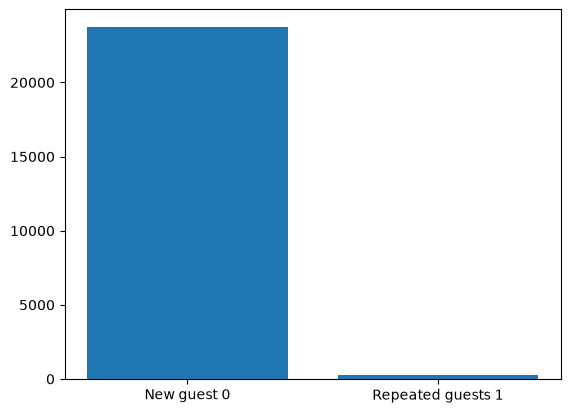

In [194]:
# 3
compare_rete = df_clean[df_clean['is_canceled'] == 1].groupby('is_repeated_guest')['is_canceled'].count()
compare_rete
labels = ['New guest 0', 'Repeated guests 1']
plt.bar(labels, compare_rete.values)

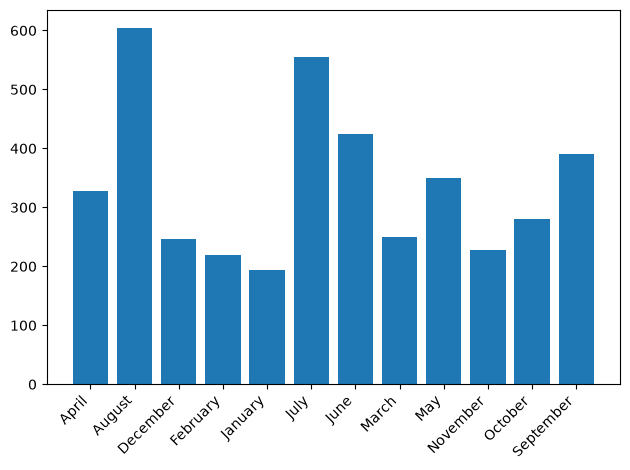

In [192]:
# 4
# what is the revenue rate per month?
revenue_rate = df_clean[df_clean['is_canceled']==0].groupby('arrival_date_month')['revenue'].mean()
plt.bar(revenue_rate.index, revenue_rate.values)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
# df_clean.groupby('arrival_date_month')[['is_canceled', 'revenue']].mean()

## Conclusion

In a short markdown note below, summarise **3 things you learned** about hotel bookings from this analysis (e.g. which hotel cancels more, when cancellations peak, what drives price).

1. Profits increase during the summer, as we observed in July and August.
2. People prefer booking city hotels over resorts.
3. New guests have high cancellation rates.

*Write your conclusions here...*